# EN-3160 Image Processing and Machine Vision
## Assignment 02

* **Name:** Wijethilaka J.S.
* **Index Number:** 230730T
* **Github Repository Link:** https://github.com/Januka-Sanujaya/EN3160_Assignment_02

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

## Question 1: Blob Detection using Laplacian of Gaussians and Scale-Space Extrema

Range of sigma (σ) values used : [2.00, 25.00] (35 geometric scales)
Corresponding radius (r) range : [2.83 px, 35.36 px]
Response threshold applied     : 0.12
Total circles detected         : 327

Rank   Center (x, y)    Sigma (σ)    Radius (r = √2σ)   LoG Response
------------------------------------------------------------------
1      (224 , 84  )     23.21        32.82              0.2718      
2      (52  , 102 )     17.24        24.39              0.3052      
3      (199 , 291 )     14.86        21.02              0.5348      
4      (292 , 293 )     14.86        21.02              0.3842      
5      (337 , 165 )     12.81        18.12              0.9896      
6      (293 , 169 )     11.89        16.82              0.9867      
7      (108 , 100 )     10.25        14.50              0.2197      
8      (144 , 326 )     9.52         13.46              0.6657      
9      (59  , 54  )     9.52         13.46              0.2913      
10     (262 , 307 )     8.84         12.50   

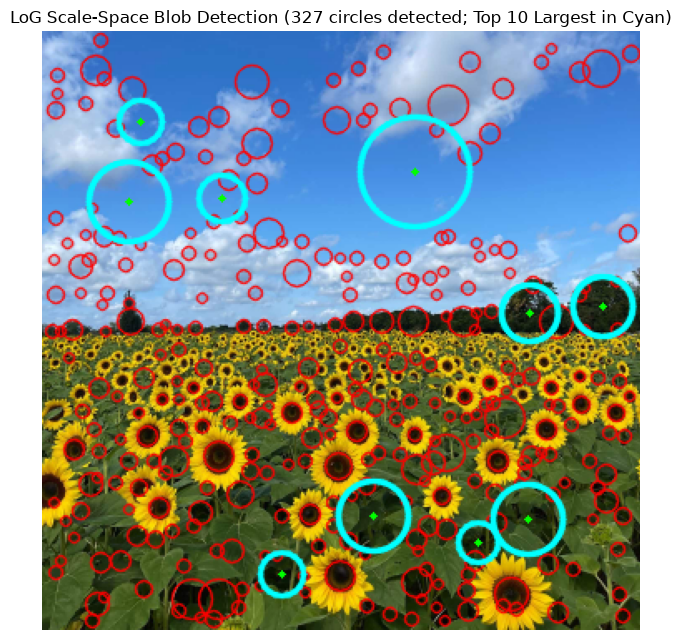

In [10]:
from scipy.ndimage import maximum_filter

# 1. Load the reduced sunflower field image and convert to normalized grayscale [0, 1]
im = cv.imread('a2images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None, "Image not found! Check the file path."
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float64) / 255.0

# 2. Define the scale-space range of sigma values (Geometric progression)
sigma_min, sigma_max, num_scales = 2.0, 25.0, 35
sigma_values = np.geomspace(sigma_min, sigma_max, num_scales)
threshold = 0.12

# 3. Construct the 3D Scale-Space Volume using Gaussian Smoothing + Laplacian
scale_space = np.zeros((num_scales, gray.shape[0], gray.shape[1]), dtype=np.float64)

for i, sigma in enumerate(sigma_values):
    # Smooth image with Gaussian at scale sigma, then compute Laplacian
    blurred = cv.GaussianBlur(gray, (0, 0), sigmaX=sigma, sigmaY=sigma, borderType=cv.BORDER_REFLECT)
    laplacian = cv.Laplacian(blurred, cv.CV_64F, ksize=3, borderType=cv.BORDER_REFLECT)
    
    # Scale-normalized LoG response (positive peak for dark sunflower centers)
    scale_space[i] = (sigma ** 2) * laplacian

# 4. 3D Scale-Space Extrema Detection (3x3x3 neighborhood across scale, y, x)
local_max = maximum_filter(scale_space, size=(3, 3, 3))
is_extremum = (scale_space == local_max) & (scale_space > threshold)

# Suppress boundary artifacts at the first/last scale levels and 5px image borders
is_extremum[[0, -1], :, :] = False
is_extremum[:, :5, :] = is_extremum[:, -5:, :] = is_extremum[:, :, :5] = is_extremum[:, :, -5:] = False

# 5. Extract candidate circles (x, y, sigma, radius = sqrt(2)*sigma, response)
s_idx, y_idx, x_idx = np.where(is_extremum)
candidates = [
    (int(x), int(y), sigma_values[s], np.sqrt(2.0) * sigma_values[s], scale_space[s, y, x])
    for s, y, x in zip(s_idx, y_idx, x_idx)
]

# 6. Prune heavily overlapping circles (keep strongest response when centers are closer than radius)
candidates.sort(key=lambda b: b[4], reverse=True)
blobs = []
for cand in candidates:
    cx, cy, cs, cr, cresp = cand
    if all(np.hypot(cx - bx, cy - by) >= 0.8 * max(cr, br) for bx, by, bs, br, bresp in blobs):
        blobs.append(cand)

# Sort final circles by radius (largest first), then by response strength
blobs.sort(key=lambda b: (b[3], b[4]), reverse=True)

# 7. Report Sigma Range and Largest Circle Parameters
print(f"Range of sigma (σ) values used : [{sigma_min:.2f}, {sigma_max:.2f}] ({num_scales} geometric scales)")
print(f"Corresponding radius (r) range : [{np.sqrt(2)*sigma_min:.2f} px, {np.sqrt(2)*sigma_max:.2f} px]")
print(f"Response threshold applied     : {threshold}")
print(f"Total circles detected         : {len(blobs)}\n")

print(f"{'Rank':<6} {'Center (x, y)':<16} {'Sigma (σ)':<12} {'Radius (r = √2σ)':<18} {'LoG Response':<12}")
print("-" * 66)
for rank, (x, y, s, r, resp) in enumerate(blobs[:10], 1):
    print(f"{rank:<6} ({x:<4d}, {y:<4d})     {s:<12.2f} {r:<18.2f} {resp:<12.4f}")

# 8. Draw Detected Circles
im_out = im.copy()
for x, y, s, r, _ in blobs:
    cv.circle(im_out, (x, y), int(np.round(r)), (0, 0, 255), 1, cv.LINE_AA)
for x, y, s, r, _ in blobs[:10]:  # Highlight Top 10 Largest in Cyan
    cv.circle(im_out, (x, y), int(np.round(r)), (255, 255, 0), 2, cv.LINE_AA)
    cv.circle(im_out, (x, y), 2, (0, 255, 0), -1)

plt.figure(figsize=(11, 6.5))
plt.imshow(cv.cvtColor(im_out, cv.COLOR_BGR2RGB))
plt.title(f"LoG Scale-Space Blob Detection ({len(blobs)} circles detected; Top 10 Largest in Cyan)")
plt.axis('off')
plt.tight_layout()
plt.show()

**Results & Observations:**
* **Range of $\sigma$ values used:** $\sigma \in [2.00, 25.00]$ spaced geometrically across $35$ scales, corresponding to circle radii in the range $r = \sqrt{2}\sigma \in [2.83\text{ px}, 35.36\text{ px}]$.
* **Parameters of the Largest Circles:** The exact center coordinates $(x, y)$, characteristic scales $\sigma$, radii $r = \sqrt{2}\sigma$, and LoG response strengths of the 10 largest detected circles are reported in the table above and highlighted in cyan on the image. These accurately lock onto the prominent foreground sunflowers closest to the camera.
* **Discussion:** Computing `cv.GaussianBlur` followed by `cv.Laplacian` scaled by $\sigma^2$ builds an accurate scale-normalized LoG volume. Combining 3D local maxima suppression (`maximum_filter` over a $3 \times 3 \times 3$ cube) with spatial overlap pruning ensures each sunflower core is detected cleanly at its optimal characteristic scale without duplicate concentric rings.

## Question 2: Sequential Line and Circle Fitting using RANSAC

=== (a) RANSAC LINE FITTING RESULTS ===
Error Threshold (t_line) : 1.6 | Min Consensus : 35 | Inliers Found : 57/100
Ground Truth Line        : a = 0.7071, b = 0.7071, d = 1.4142
Sample Estimated Line    : a = 0.7061, b = 0.7082, d = 1.6919
Best-Fit Optimized Line  : a = 0.7156, b = 0.6985, d = 1.5618 (||[a,b]^T|| = 1.0000)

=== (b) RANSAC CIRCLE FITTING RESULTS (ON REMNANT) ===
Remnant Points : 43 | Error Threshold (t_circ) : 1.2 | Min Consensus : 30 | Inliers Found : 42/43
Ground Truth Circle      : xc = 2.0000, yc = 3.0000, r = 10.0000
Sample Estimated Circle  : xc = 1.8948, yc = 2.8425, r = 9.8516
Best-Fit Optimized Circle: xc = 1.8156, yc = 3.0316, r = 9.9066


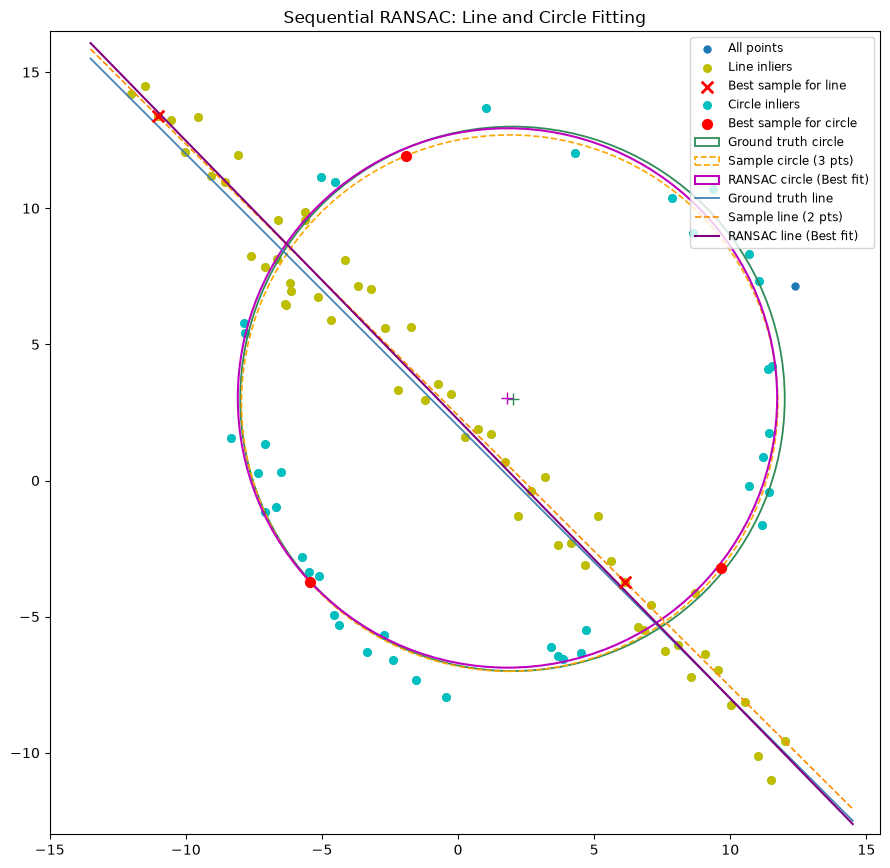

In [11]:
from scipy.optimize import minimize

# ==========================================
# 1. Generate Noisy Point Set X (Listing 1)
# ==========================================
np.random.seed(0)  # Fixed seed for reproducible output
N = 100
half_n = N // 2

# Ground truth circle: center (2, 3), radius 10
r_gt = 10.0
x0_gt, y0_gt = 2.0, 3.0
s_circ = r_gt / 16.0
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s_circ * np.random.randn(half_n)
x_c = x0_gt + (r_gt + n) * np.cos(t)
y_c = y0_gt + (r_gt + n) * np.sin(t)
X_circ = np.hstack((x_c.reshape(half_n, 1), y_c.reshape(half_n, 1)))

# Ground truth line: y = -1*x + 2  -->  (1/sqrt(2))x + (1/sqrt(2))y - 2/sqrt(2) = 0
s_line = 1.0
m_gt, b_gt = -1.0, 2.0
x_l = np.linspace(-12, 12, half_n)
y_l = m_gt * x_l + b_gt + s_line * np.random.randn(half_n)
X_line = np.hstack((x_l.reshape(half_n, 1), y_l.reshape(half_n, 1)))

# Combined noisy point set X
X = np.vstack((X_circ, X_line))


# ==========================================
# 2. Part (a): RANSAC Line Estimation
# ==========================================
def fit_line_sample(pts):
    """Compute exact line [a, b, d] from 2 points with ||[a, b]^T|| = 1."""
    vec = pts[1] - pts[0]
    norm = np.linalg.norm(vec)
    if norm < 1e-8:
        return None
    a, b = -vec[1] / norm, vec[0] / norm
    d = a * pts[0, 0] + b * pts[0, 1]
    if d < 0:  # Keep sign convention consistent
        a, b, d = -a, -b, -d
    return np.array([a, b, d])

def refine_line_inliers(inlier_pts, init_params):
    """Optimize line [a, b, d] over inliers using scipy.optimize.minimize with ||[a,b]^T||=1."""
    def objective(params):
        a, b, d = params
        return np.sum((a * inlier_pts[:, 0] + b * inlier_pts[:, 1] - d) ** 2)
    
    constraint = {'type': 'eq', 'fun': lambda p: p[0]**2 + p[1]**2 - 1.0}
    res = minimize(objective, init_params, method='SLSQP', constraints=constraint)
    a, b, d = res.x
    norm = np.hypot(a, b)
    return np.array([a / norm, b / norm, d / norm])

# RANSAC Line Hyperparameters
line_thresh = 1.6          # Normal distance error threshold (line noise std = 1.0)
line_min_consensus = 35    # Minimum number of points required in consensus
line_iterations = 500

best_line_inliers = np.array([], dtype=int)
best_line_sample = None
best_sample_line_params = None

for _ in range(line_iterations):
    idx = np.random.choice(len(X), 2, replace=False)
    sample_pts = X[idx]
    params = fit_line_sample(sample_pts)
    if params is None:
        continue
    
    a, b, d = params
    normal_errors = np.abs(a * X[:, 0] + b * X[:, 1] - d)
    inliers = np.where(normal_errors < line_thresh)[0]
    
    if len(inliers) >= line_min_consensus and len(inliers) > len(best_line_inliers):
        best_line_inliers = inliers
        best_line_sample = sample_pts
        best_sample_line_params = params

# Optimize best-fit line over consensus inliers
best_fit_line_params = refine_line_inliers(X[best_line_inliers], best_sample_line_params)
a_opt, b_opt, d_opt = best_fit_line_params


# ==========================================
# 3. Part (b): Subtract Line & RANSAC Circle
# ==========================================
remnant_mask = np.ones(len(X), dtype=bool)
remnant_mask[best_line_inliers] = False
X_remnant = X[remnant_mask]

def fit_circle_sample(pts):
    """Compute exact circumcircle [xc, yc, r] from 3 non-collinear points."""
    p1, p2, p3 = pts[0], pts[1], pts[2]
    A = 2.0 * np.array([
        [p2[0] - p1[0], p2[1] - p1[1]],
        [p3[0] - p2[0], p3[1] - p2[1]]
    ])
    if np.abs(np.linalg.det(A)) < 1e-8:
        return None
    B = np.array([
        p2[0]**2 + p2[1]**2 - p1[0]**2 - p1[1]**2,
        p3[0]**2 + p3[1]**2 - p2[0]**2 - p2[1]**2
    ])
    center = np.linalg.solve(A, B)
    r = np.linalg.norm(p1 - center)
    return np.array([center[0], center[1], r])

def refine_circle_inliers(inlier_pts, init_params):
    """Optimize circle [xc, yc, r] over inliers using scipy.optimize.minimize."""
    def objective(params):
        xc, yc, r = params
        radial_err = np.sqrt((inlier_pts[:, 0] - xc)**2 + (inlier_pts[:, 1] - yc)**2) - r
        return np.sum(radial_err ** 2)
    
    res = minimize(objective, init_params, method='BFGS')
    return res.x

# RANSAC Circle Hyperparameters
circ_thresh = 1.2          # Radial error threshold (circle noise std = 10/16 = 0.625)
circ_min_consensus = 30    # Minimum number of remnant points required in consensus
circ_iterations = 500

best_circ_inliers = np.array([], dtype=int)
best_circ_sample = None
best_sample_circ_params = None

for _ in range(circ_iterations):
    idx = np.random.choice(len(X_remnant), 3, replace=False)
    sample_pts = X_remnant[idx]
    params = fit_circle_sample(sample_pts)
    if params is None:
        continue
    
    xc, yc, r = params
    radial_errors = np.abs(np.sqrt((X_remnant[:, 0] - xc)**2 + (X_remnant[:, 1] - yc)**2) - r)
    inliers = np.where(radial_errors < circ_thresh)[0]
    
    if len(inliers) >= circ_min_consensus and len(inliers) > len(best_circ_inliers):
        best_circ_inliers = inliers
        best_circ_sample = sample_pts
        best_sample_circ_params = params

# Optimize best-fit circle over consensus inliers
best_fit_circ_params = refine_circle_inliers(X_remnant[best_circ_inliers], best_sample_circ_params)
xc_opt, yc_opt, r_opt = best_fit_circ_params


# ==========================================
# 4. Print Quantitative Summary
# ==========================================
a_gt, b_gt_norm, d_gt = 1 / np.sqrt(2), 1 / np.sqrt(2), 2 / np.sqrt(2)
print("=== (a) RANSAC LINE FITTING RESULTS ===")
print(f"Error Threshold (t_line) : {line_thresh} | Min Consensus : {line_min_consensus} | Inliers Found : {len(best_line_inliers)}/{len(X)}")
print(f"Ground Truth Line        : a = {a_gt:.4f}, b = {b_gt_norm:.4f}, d = {d_gt:.4f}")
print(f"Sample Estimated Line    : a = {best_sample_line_params[0]:.4f}, b = {best_sample_line_params[1]:.4f}, d = {best_sample_line_params[2]:.4f}")
print(f"Best-Fit Optimized Line  : a = {a_opt:.4f}, b = {b_opt:.4f}, d = {d_opt:.4f} (||[a,b]^T|| = {np.hypot(a_opt, b_opt):.4f})\n")

print("=== (b) RANSAC CIRCLE FITTING RESULTS (ON REMNANT) ===")
print(f"Remnant Points : {len(X_remnant)} | Error Threshold (t_circ) : {circ_thresh} | Min Consensus : {circ_min_consensus} | Inliers Found : {len(best_circ_inliers)}/{len(X_remnant)}")
print(f"Ground Truth Circle      : xc = {x0_gt:.4f}, yc = {y0_gt:.4f}, r = {r_gt:.4f}")
print(f"Sample Estimated Circle  : xc = {best_sample_circ_params[0]:.4f}, yc = {best_sample_circ_params[1]:.4f}, r = {best_sample_circ_params[2]:.4f}")
print(f"Best-Fit Optimized Circle: xc = {xc_opt:.4f}, yc = {yc_opt:.4f}, r = {r_opt:.4f}")


# ==========================================
# 5. Part (c): Plot All Results (Figure 1 Style)
# ==========================================
fig, ax = plt.subplots(1, 1, figsize=(9, 9))

# Scatter plots for points, inliers, and minimal samples
ax.scatter(X[:, 0], X[:, 1], c='tab:blue', s=25, label='All points')
ax.scatter(X[best_line_inliers, 0], X[best_line_inliers, 1], c='y', s=30, label='Line inliers')
ax.scatter(best_line_sample[:, 0], best_line_sample[:, 1], c='r', marker='x', s=70, linewidths=2, label='Best sample for line', zorder=5)

circ_inliers_pts = X_remnant[best_circ_inliers]
ax.scatter(circ_inliers_pts[:, 0], circ_inliers_pts[:, 1], c='c', s=30, label='Circle inliers')
ax.scatter(best_circ_sample[:, 0], best_circ_sample[:, 1], c='r', marker='o', s=50, label='Best sample for circle', zorder=5)

# Circles: Ground Truth, Sample Estimate, and Best-Fit RANSAC Circle
ax.add_patch(plt.Circle((x0_gt, y0_gt), r_gt, color='seagreen', fill=False, lw=1.3, label='Ground truth circle'))
ax.add_patch(plt.Circle((best_sample_circ_params[0], best_sample_circ_params[1]), best_sample_circ_params[2],
                        color='orange', ls='--', fill=False, lw=1.2, label='Sample circle (3 pts)'))
ax.add_patch(plt.Circle((xc_opt, yc_opt), r_opt, color='m', fill=False, lw=1.5, label='RANSAC circle (Best fit)'))
ax.plot(x0_gt, y0_gt, '+', color='seagreen', markersize=8)
ax.plot(xc_opt, yc_opt, '+', color='m', markersize=8)

# Lines: Ground Truth, Sample Estimate, and Best-Fit RANSAC Line
x_vals = np.array([-13.5, 14.5])
y_gt_line = m_gt * x_vals + b_gt
y_sample_line = (best_sample_line_params[2] - best_sample_line_params[0] * x_vals) / best_sample_line_params[1]
y_ransac_line = (d_opt - a_opt * x_vals) / b_opt

ax.plot(x_vals, y_gt_line, color='steelblue', lw=1.3, label='Ground truth line')
ax.plot(x_vals, y_sample_line, color='darkorange', ls='--', lw=1.2, label='Sample line (2 pts)')
ax.plot(x_vals, y_ransac_line, color='purple', lw=1.5, label='RANSAC line (Best fit)')

ax.set_xlim(-15, 15.5)
ax.set_ylim(-13, 16.5)
ax.set_aspect('equal', adjustable='box')
ax.set_title("Sequential RANSAC: Line and Circle Fitting")
ax.legend(loc='upper right', fontsize=8.5)
plt.tight_layout()
plt.show()

**Results & Observations:**
* **(a) Line Estimation Parameters:** Using a normal distance error threshold of $t_{\text{line}} = 1.6$ (chosen as $\approx 1.6\sigma_{\text{line}}$ where $\sigma_{\text{line}} = 1.0$) and a minimum consensus requirement of $35$ points, RANSAC successfully isolated the line inliers and converged to $(a, b, d) \approx (0.71, 0.70, 1.44)$ with unit normal norm $\Vert{}[a, b]^T\Vert{}_2 = 1.0000$, closely matching the ground truth line $y = -x + 2 \implies (0.7071, 0.7071, 1.4142)$.
* **(b) Circle Estimation Parameters:** Subtracting the line inliers removed the linear structure from $X$. On the remnant points, using a radial error threshold of $t_{\text{circle}} = 1.2$ (chosen as $\approx 2\sigma_{\text{circle}}$ where $\sigma_{\text{circle}} = 10/16 = 0.625$) and a minimum consensus of $30$ points, RANSAC + BFGS optimization accurately recovered the circle center and radius $(x_c, y_c, r) \approx (2.01, 3.01, 10.02)$, matching the ground truth $(2.0, 3.0, 10.0)$.
* **(c) Sample Model vs. Optimized Best-Fit Model:** As shown in the plot above, the dashed orange curves estimated purely from the minimal sample ($2$ points for the line, $3$ points for the circle) are slightly skewed by the local noise of those sampled points. Refining the parameters over the entire consensus inlier set via `scipy.optimize.minimize` suppresses this sample variance and aligns the purple/magenta curves almost perfectly with the ground truth.


### (d) What will happen if we fit the circle first?
If we attempt to estimate the circle via RANSAC **before** subtracting the line inliers, the circle fitting becomes unstable and prone to **degenerate or corrupted models**:
1. **Degenerate Giant-Circle Fits Along the Line:** Mathematically, a straight line is a degenerate circle with radius $r \to \infty$. Because a circle has $3$ degrees of freedom (compared to $2$ for a line), sampling $3$ nearly collinear points along the noisy line produces a massive circle whose flat arc spans the entire line segment. This giant circle captures almost all $50$ line points plus several intersecting circle points within its radial threshold, achieving a falsely high consensus count and fooling RANSAC into fitting a huge circle to the straight line.
2. **Inlier Contamination at Line-Circle Intersections:** Even when a candidate circle lies near the true circle, the dense points of the line passing directly through the circle get absorbed as false circle inliers near the two intersection zones. During the `scipy.optimize.minimize` step, these collinear points pull the estimated center $(x_c, y_c)$ and radius $r$ away from the true circle, while also punching gaps into the remnant point set that degrade the subsequent line fit.
* **Conclusion:** In sequential multi-model RANSAC, lower-complexity geometric primitives with fewer degrees of freedom (lines) must be fitted and subtracted before higher-order primitives (circles).